# 04. Chia dữ liệu và đánh giá (Bước 5 và 6)

**Nhiệm vụ của notebook này:** kiểm tra mô hình trên dữ liệu chưa thấy và đo cho đúng bằng Recall, ngưỡng (mục 2.6, 2.7).

Chạy từng ô từ trên xuống. Notebook tự đọc `data.csv` (Colab sẽ hỏi bạn tải lên; trên máy thì đặt tại `data/data.csv`).

Nên đọc theo thứ tự các notebook 01 → 06. Phần trước: 03.

In [1]:
# Ô thiết lập: nạp thư viện và đọc dữ liệu
import io, os, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, roc_auc_score, confusion_matrix)

warnings.filterwarnings("ignore")
SEED = 42                               # hạt giống ngẫu nhiên cố định: chạy lại ra đúng kết quả cũ
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})


def doc_du_lieu():
    """Tìm data.csv trên máy; nếu đang ở Colab thì xin người dùng tải lên."""
    for p in ["data/data.csv", "../data/data.csv", "data.csv"]:
        if os.path.exists(p):
            print("Đọc dữ liệu từ", p)
            return pd.read_csv(p, sep=";")
    try:
        from google.colab import files
        print("Hãy chọn tệp data.csv trên máy của bạn ...")
        up = files.upload()
        return pd.read_csv(io.BytesIO(list(up.values())[0]), sep=";")
    except ImportError:
        raise FileNotFoundError("Không thấy data.csv. Hãy đặt tệp vào thư mục data/.")


raw = doc_du_lieu()
raw.columns = [c.strip() for c in raw.columns]      # bỏ khoảng trắng/tab thừa ở tên cột
print("Kích thước:", raw.shape)

# --- Chuẩn bị chung (lặp lại ở mỗi notebook để mỗi tệp chạy độc lập) ---
d = raw[raw.Target != "Enrolled"].reset_index(drop=True)
d["y"] = (d.Target == "Dropout").astype(int)          # 1 = bỏ học (nguy cơ), 0 = tốt nghiệp (an toàn)
ENTRY = ["Tuition fees up to date", "Debtor", "Scholarship holder", "Age at enrollment"]
YEAR1 = ["Curricular units 1st sem (approved)", "Curricular units 1st sem (grade)",
         "Curricular units 2nd sem (approved)", "Curricular units 2nd sem (grade)"]
COMPACT = ENTRY + YEAR1
ADMISSION_ONLY = ["Admission grade", "Previous qualification (grade)", "Age at enrollment",
                  "Scholarship holder", "Debtor", "Tuition fees up to date", "Gender", "Application order"]
ALL = [c for c in d.columns if c not in ("Target", "y")]
y = d.y.values
train_idx, test_idx = train_test_split(np.arange(len(d)), test_size=0.2, stratify=d.y, random_state=SEED)
ytr, yte = y[train_idx], y[test_idx]


def chuan_bi(cols, chuan_hoa=True):
    """Ma trận X cho tập huấn luyện và kiểm tra; chuẩn hóa bằng trung bình, độ lệch chuẩn của TẬP HUẤN LUYỆN."""
    X = d[cols].values.astype(float)
    Xtr, Xte = X[train_idx], X[test_idx]
    if chuan_hoa:
        mu, sd = Xtr.mean(0), Xtr.std(0); sd[sd == 0] = 1
        Xtr, Xte = (Xtr - mu) / sd, (Xte - mu) / sd
    return Xtr, Xte


def hoi_quy_sklearn(X, y):
    try:
        return LogisticRegression(penalty=None, max_iter=5000).fit(X, y)
    except Exception:
        return LogisticRegression(C=np.inf, max_iter=5000).fit(X, y)


def sigmoid(z):
    z = np.clip(z, -500, 500)
    return np.where(z >= 0, 1 / (1 + np.exp(-z)), np.exp(z) / (1 + np.exp(z)))


def cross_entropy(p, y):
    p = np.clip(p, 1e-12, 1 - 1e-12)
    return float(-np.mean(y * np.log(p) + (1 - y) * np.log(1 - p)))


Đọc dữ liệu từ ../data/data.csv
Kích thước: (4424, 37)


---
# Bước 5. Chia dữ liệu và overfitting (mục 2.6 của đề: xác suất thống kê)

## Vì sao cần bước này
Học thuộc "bàn cũ" thì dễ. Câu hỏi thật là: **gặp lớp sinh viên mới thì mô hình có đoán đúng không?** Mức phạt trên dữ liệu đã học chỉ là ước lượng *lạc quan*, vì tham số đã được chỉnh để khớp chính dữ liệu đó. Vì vậy ta **giấu đi** một phần dữ liệu (tập kiểm tra), không cho mô hình thấy, chỉ dùng để chấm điểm cuối.

## Ý chính
- **Chia phân tầng 80/20:** giữ nguyên tỉ lệ nhãn ở cả hai tập, để tập kiểm tra không vô tình dễ hay khó hơn. **Seed cố định** để chạy lại ra đúng kết quả.
- **Overfitting:** mô hình nhớ cả nhiễu của dữ liệu huấn luyện: điểm trên tập huấn luyện cao mà trên tập mới thấp. **Underfitting:** mô hình quá đơn giản, điểm thấp ở cả hai.
- Hồi quy Logistic chỉ có chín tham số cho gần ba nghìn mẫu nên rất khó quá khớp.
- **Sai số của phép đo.** Accuracy đo trên n mẫu có sai số chuẩn xấp xỉ √(p(1−p)/n). Với 726 mẫu kiểm tra và Accuracy khoảng 90%, sai số này cỡ 1,1 điểm phần trăm, tức khoảng tin cậy 95% xấp xỉ ±2,2 điểm. Chênh lệch nhỏ hơn thế **chưa đủ để kết luận**.

In [2]:
# So sánh điểm trên tập huấn luyện và tập kiểm tra (cấu hình chính, 8 cột)
Xa, Xb = chuan_bi(COMPACT, True)
mo_hinh = hoi_quy_sklearn(Xa, ytr)
p_tr, p_te = mo_hinh.predict_proba(Xa)[:, 1], mo_hinh.predict_proba(Xb)[:, 1]
print(f"Huấn luyện: accuracy {accuracy_score(ytr, p_tr >= .5):.3f}, mất mát {cross_entropy(p_tr, ytr):.3f}")
print(f"Kiểm tra  : accuracy {accuracy_score(yte, p_te >= .5):.3f}, mất mát {cross_entropy(p_te, yte):.3f}")

acc = accuracy_score(yte, p_te >= .5)
se = np.sqrt(acc * (1 - acc) / len(yte))
print(f"\nSai số chuẩn của accuracy ≈ {se:.4f}; khoảng tin cậy 95% ≈ ±{1.96 * se:.3f} (±{1.96 * se * 100:.1f} điểm phần trăm)")

Huấn luyện: accuracy 0.879, mất mát 0.330
Kiểm tra  : accuracy 0.899, mất mát 0.300

Sai số chuẩn của accuracy ≈ 0.0112; khoảng tin cậy 95% ≈ ±0.022 (±2.2 điểm phần trăm)


## Đọc kết quả
- Điểm trên hai tập gần nhau, không có khoảng cách đáng ngại: **không thấy dấu hiệu overfitting** với mô hình đơn giản này. (Mất mát trên tập kiểm tra còn thấp hơn một chút, do tập kiểm tra ngẫu nhiên hơi dễ; đó không phải điều bất thường.)
- Khoảng tin cậy cỡ ±2,2 điểm cho ta quy tắc đọc kết quả: **hai cấu hình chênh nhau dưới 2 điểm Accuracy thì không kết luận được cấu hình nào tốt hơn.**
- Ta mới chia **một lần**, nên chưa biết kết quả ổn định đến đâu giữa các lần chia. Kiểm tra chéo (k-fold) là hướng mở rộng. Hãy nêu đây là hạn chế.

## Thầy có thể hỏi
- *Vì sao phải giấu một phần dữ liệu?* Để có ước lượng không lạc quan về chất lượng trên dữ liệu chưa thấy.
- *Làm sao biết mô hình quá khớp?* So điểm huấn luyện với kiểm tra: huấn luyện cao hẳn mà kiểm tra thấp là dấu hiệu.
- *Chia phân tầng để làm gì?* Giữ tỉ lệ nhãn như nhau ở hai tập, nhất là khi lớp bị lệch.

---
# Bước 6. Đánh giá: đo "đoán tốt" cho đúng (mục 2.7 của đề)

## Vì sao cần bước này
Hai kiểu sai có **giá rất khác nhau**:
- Báo nhầm một em ổn là có nguy cơ: chỉ tốn một buổi gặp mặt.
- Bỏ sót một em sắp nghỉ học: em đó "nổ" thật.

Nên ta không chỉ nhìn Accuracy.

## Bốn con số của ma trận nhầm lẫn
**TP** (đoán bỏ học và đúng), **FN** (bỏ sót: thật sự bỏ học mà đoán an toàn), **FP** (báo nhầm), **TN** (đoán an toàn và đúng).

| Độ đo | Ý nghĩa trong bài này |
|---|---|
| Accuracy = (TP+TN)/n | Tỉ lệ đoán đúng chung (dễ đánh lừa khi lớp lệch) |
| Precision = TP/(TP+FP) | Trong số em bị báo nguy cơ, bao nhiêu em thật sự bỏ học |
| **Recall** = TP/(TP+FN) | Trong số em thật sự bỏ học, ta **bắt được bao nhiêu** |
| F1 | Trung bình điều hòa của Precision và Recall |
| ROC-AUC | Xác suất mô hình chấm em bỏ học cao hơn em an toàn, không phụ thuộc ngưỡng |

Ở bài này **Recall của lớp bỏ học là độ đo quan trọng nhất**.

In [3]:
def do_metrics(y_that, p, nguong=0.5):
    yh = (p >= nguong).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_that, yh).ravel()
    return {"accuracy": accuracy_score(y_that, yh), "precision": precision_score(y_that, yh, zero_division=0),
            "recall": recall_score(y_that, yh), "f1": f1_score(y_that, yh), "auc": roc_auc_score(y_that, p),
            "TP": tp, "FN": fn, "FP": fp, "TN": tn}


# Bốn cấu hình: đổi lượng thông tin đưa vào mô hình
CAU_HINH = {"A. Lúc nhập học (8 cột)": ADMISSION_ONLY,
            "B1. Nhập học + hết HK1 (6 cột)": ENTRY + YEAR1[:2],
            "B. Nhập học + hết HK2 (8 cột)": COMPACT,
            "C. Đầy đủ 35 cột": ALL}
hang, xac_suat_B = [], None
for ten_ch, cot in CAU_HINH.items():
    Xa, Xb = chuan_bi(cot, True)
    m = hoi_quy_sklearn(Xa, ytr)
    pte = m.predict_proba(Xb)[:, 1]
    hang.append({"cấu hình": ten_ch, **do_metrics(yte, pte)})
    if ten_ch.startswith("B. "):
        xac_suat_B = pte
bang_ch = pd.DataFrame(hang)
display(bang_ch[["cấu hình", "accuracy", "precision", "recall", "f1", "auc"]].round(3))

,cấu hình,accuracy,precision,recall,f1,auc
0,A. Lúc nhập học (8 cột),0.751,0.727,0.581,0.646,0.815
1,B1. Nhập học + hết HK1 (6 cột),0.875,0.864,0.806,0.834,0.914
2,B. Nhập học + hết HK2 (8 cột),0.899,0.884,0.856,0.869,0.940
3,C. Đầy đủ 35 cột,0.945,0.936,0.923,0.929,0.973


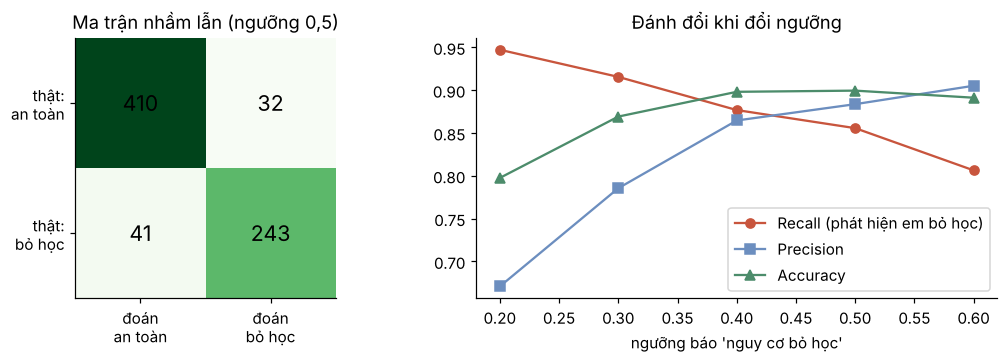

,ngưỡng,recall,precision,accuracy,TP,FN,FP
0,0.2,0.947,0.671,0.798,269,15,132
1,0.3,0.915,0.785,0.869,260,24,71
2,0.4,0.877,0.865,0.898,249,35,39
3,0.5,0.856,0.884,0.899,243,41,32
4,0.6,0.806,0.905,0.891,229,55,24


In [4]:
# Ma trận nhầm lẫn và việc đổi ngưỡng báo động (cấu hình B)
cm = confusion_matrix(yte, (xac_suat_B >= 0.5).astype(int))
fig, ax = plt.subplots(1, 2, figsize=(10, 3.4))
ax[0].imshow(cm, cmap="Greens")
for i in range(2):
    for j in range(2):
        ax[0].text(j, i, cm[i, j], ha="center", va="center", fontsize=14)
ax[0].set_xticks([0, 1]); ax[0].set_xticklabels(["đoán\nan toàn", "đoán\nbỏ học"])
ax[0].set_yticks([0, 1]); ax[0].set_yticklabels(["thật:\nan toàn", "thật:\nbỏ học"]); ax[0].set_title("Ma trận nhầm lẫn (ngưỡng 0,5)")

ngs = [0.2, 0.3, 0.4, 0.5, 0.6]
bang_ng = pd.DataFrame([{"ngưỡng": t, **do_metrics(yte, xac_suat_B, t)} for t in ngs])
ax[1].plot(bang_ng.ngưỡng, bang_ng.recall, "o-", color="#C8553D", label="Recall (phát hiện em bỏ học)")
ax[1].plot(bang_ng.ngưỡng, bang_ng.precision, "s-", color="#6C8EBF", label="Precision")
ax[1].plot(bang_ng.ngưỡng, bang_ng.accuracy, "^-", color="#4C8C6B", label="Accuracy")
ax[1].set_xlabel("ngưỡng báo 'nguy cơ bỏ học'"); ax[1].legend(); ax[1].set_title("Đánh đổi khi đổi ngưỡng")
plt.tight_layout(); plt.show()
display(bang_ng[["ngưỡng", "recall", "precision", "accuracy", "TP", "FN", "FP"]].round(3))

## Đọc kết quả
- **Thông tin càng nhiều thì Recall càng cao, nhưng phải trả giá bằng thời điểm.** Chỉ dùng thông tin lúc nhập học (cấu hình A), Recall khoảng 58%: gần một nửa số em bỏ học bị bỏ sót. Thêm kết quả học kỳ 1 (B1) lên khoảng 81%. Thêm học kỳ 2 (B) khoảng 86%. Dùng đủ 35 cột (C) khoảng 92%.
- **Nhưng cẩn thận với cấu hình dùng học kỳ 2.** Điểm HK2 bằng 0 thường nghĩa là em đã nghỉ (Bước 1), nên B và C phần nào đang "dự đoán điều đã xảy ra". Nếu mục tiêu là *cảnh báo sớm thật sự* thì **B1 (hết học kỳ 1)** mới là phương án thực tế.
- Chênh giữa A và các cấu hình sau rất lớn so với sai số ±2,2 điểm, nên đáng tin. Chênh giữa B1 và B (khoảng 2,4 điểm Accuracy) chỉ ở ngưỡng biên.
- **Ngưỡng không bắt buộc là 0,5.** Hạ xuống 0,3 thì bắt khoảng 91,5% em bỏ học (bỏ sót 24 em) đổi lại báo nhầm nhiều hơn (71 em); ở 0,5 thì bỏ sót 41, báo nhầm 32. Nếu mỗi lần báo nhầm chỉ tốn một buổi gặp mặt còn mỗi lần bỏ sót là mất một sinh viên, ngưỡng thấp hơn 0,5 là lựa chọn hợp lý. *Chọn ngưỡng là quyết định của nhà trường, không phải của thuật toán.* AUC không đổi khi đổi ngưỡng vì thứ hạng xác suất không đổi.

## Thầy có thể hỏi
- *Vì sao Recall quan trọng hơn Accuracy ở bài này?* Vì bỏ sót một em bỏ học đắt hơn báo nhầm, và lớp bỏ học chỉ chiếm 39%.
- *Cấu hình nào dùng được cho cảnh báo sớm?* B1 (đến hết học kỳ 1); các cấu hình dùng HK2 phần nào chứa sẵn đáp án.
- *AUC khác Accuracy chỗ nào?* AUC đánh giá cách mô hình *xếp thứ hạng* nguy cơ, không phụ thuộc ngưỡng cắt.